Grab the relevant columns

In [ ]:
import pandas as pd

# Load the Excel file into a Pandas DataFrame
try:
    # df = pd.read_csv('/content/quikfix.csv') # i removed row number 618 and it fixed it
    df = pd.read_csv('../../data/predictions/llm/raw/gemini_direct_video2values.csv', on_bad_lines='warn', sep=',') # skip bad lines, and explicitly set the separator
except FileNotFoundError:
    print("Error: File not found. Please make sure the file path is correct.")
    df = pd.DataFrame()  # Create an empty DataFrame to avoid further errors
if 'filename' in df.columns:
    df = df.rename(columns={'filename': '1_Link1'})
# Specify the desired columns
selected_columns = [
    '1_Link1',
    '1_Value1_Self_Direction_Thought_values',
    '1_Value1_Self_Direction_Action_values',
    '1_Value1_Stimulation_values',
    '1_Value1_Hedonism_values',
    '1_Value1_Achievement_values',
    '1_Value1_Power_Resources_values',
    '1_Value1_Power_dominance_values',
    '1_Value1_Face_values',
    '1_Value1_Security_Personal_values',
    '1_Value1_Security_Social_values',
    '1_Value1_Conformity_Rules_values',
    '1_Value1_Conformity_Interpersonal_values',
    '1_Value1_Tradition_values',
    '1_Value1_Humility_values',
    '1_Value1_Benevolence_Dependability_values',
    '1_Value1_Benevolence_Care_values',
    '1_Value1_Universalism_Concern_values',
    '1_Value1_Universalism_Nature_values',
    '1_Value1_Universalism_Tolerance_values'
]

# Create a new DataFrame with only the selected columns
if not df.empty:
    pred_df = df[selected_columns]
    # print(values_df)
else:
    print("DataFrame is empty. Cannot create a new DataFrame with selected columns.")

In [ ]:
pred_df

,1_Link1,1_Value1_Self_Direction_Thought_values,1_Value1_Self_Direction_Action_values,1_Value1_Stimulation_values,1_Value1_Hedonism_values,1_Value1_Achievement_values,1_Value1_Power_Resources_values,1_Value1_Power_dominance_values,1_Value1_Face_values,1_Value1_Security_Personal_values,1_Value1_Security_Social_values,1_Value1_Conformity_Rules_values,1_Value1_Conformity_Interpersonal_values,1_Value1_Tradition_values,1_Value1_Humility_values,1_Value1_Benevolence_Dependability_values,1_Value1_Benevolence_Care_values,1_Value1_Universalism_Concern_values,1_Value1_Universalism_Nature_values,1_Value1_Universalism_Tolerance_values
0,@alexkay_video_6783398367490854150,NaN,NaN,present,NaN,NaN,NaN,NaN,NaN,NaN,NaN,conflict,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,@alexkay_video_6807140917636648197,NaN,NaN,NaN,present,NaN,NaN,NaN,present,NaN,NaN,NaN,NaN,NaN,conflict,NaN,NaN,NaN,NaN,NaN
2,@alexkay_video_6811970678024195334,NaN,NaN,present,present,NaN,NaN,NaN,NaN,conflict,NaN,NaN,NaN,NaN,NaN,NaN,conflict,NaN,NaN,NaN
3,@alexkay_video_6905879944979631365,NaN,NaN,NaN,present,NaN,present,NaN,NaN,present,NaN,NaN,NaN,present,NaN,NaN,present,NaN,NaN,NaN
4,@alexkay_video_6925220555478027525,NaN,NaN,NaN,NaN,present,present,NaN,NaN,present,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1055,@zeuz__video_7346995193024957727,present,present,present,NaN,present,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1056,@zeuz__video_7347384674781646111,NaN,NaN,NaN,present,NaN,NaN,NaN,NaN,NaN,NaN,NaN,conflict,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1057,@zeuz__video_7347848700145700126,NaN,NaN,NaN,NaN,present,NaN,NaN,NaN,present,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1058,@zeuz__video_7348138821680139551,NaN,NaN,NaN,NaN,present,present,present,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Look for dirty data to clean

In [ ]:
for column in pred_df.columns:
    if column=='1_Link1':
        continue
    print(f"Column: {column}")
    print(pred_df[column].unique())
    print("-" * 20)

Column: 1_Value1_Self_Direction_Thought_values
[nan 'conflict' 'present']
--------------------
Column: 1_Value1_Self_Direction_Action_values
[nan 'present' 'conflict']
--------------------
Column: 1_Value1_Stimulation_values
['present' nan 'conflict']
--------------------
Column: 1_Value1_Hedonism_values
[nan 'present' 'conflict']
--------------------
Column: 1_Value1_Achievement_values
[nan 'present' 'conflict']
--------------------
Column: 1_Value1_Power_Resources_values
[nan 'present' 'conflict']
--------------------
Column: 1_Value1_Power_dominance_values
[nan 'conflict' 'present']
--------------------
Column: 1_Value1_Face_values
[nan 'present' 'conflict']
--------------------
Column: 1_Value1_Security_Personal_values
[nan 'conflict' 'present']
--------------------
Column: 1_Value1_Security_Social_values
[nan 'present' 'conflict']
--------------------
Column: 1_Value1_Conformity_Rules_values
['conflict' nan 'present']
--------------------
Column: 1_Value1_Conformity_Interpersonal_

In [ ]:
import numpy as np

def clean_values_dataframe(values_df):
    """
    Cleans the specified DataFrame by replacing invalid or inconsistent values
    in columns ending with '_values' or '_channel'.

    Args:
        values_df (pd.DataFrame): The DataFrame to clean.

    Returns:
        pd.DataFrame: The cleaned DataFrame.
    """
    # Define allowed values for different column types
    values_allowed_values = {'present', 'dominant', 'conflict', None}
    channel_allowed_values = {'verbal', 'visual', 'both', np.nan}

    for col in values_df.columns:
        if col.endswith('_values'):
            # Replace specific invalid values with None
            values_df[col] = values_df[col].replace(['none', ' ', '\xa0','0'], np.nan)
            # Normalize specific values
            values_df[col] = values_df[col].replace(['present ','1', 'pres', 'verbal',"{'present': 1}"], 'present')
            values_df[col] = values_df[col].replace(['c', 'confict','-1'], 'conflict')
            values_df[col] = values_df[col].replace(['d', 'dominant','2'], 'dominant')

        elif col.endswith('_channel'):
            # Replace specific invalid values with None
            values_df[col] = values_df[col].replace(['none', ' ', '\xa0'], np.nan)
            # Normalize specific values
            values_df[col] = values_df[col].replace(['ver', 'verbal ', 'v'], 'verbal')
            values_df[col] = values_df[col].replace(['b', 'both '], 'both')
            values_df[col] = values_df[col].replace(['c', 'confict'], 'conflict')

    return values_df


In [ ]:
pred_df = clean_values_dataframe(pred_df)
pred_df.to_csv('cleaned_video_predictions.csv', index=False)

<ipython-input-5-5631db6c1bc7>:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  values_df[col] = values_df[col].replace(['none', ' ', '\xa0','0'], np.nan)
<ipython-input-5-5631db6c1bc7>:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  values_df[col] = values_df[col].replace(['present ','1', 'pres', 'verbal',"{'present': 1}"], 'present')
<ipython-input-5-5631db6c1bc7>:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = va

Start comparing

In [ ]:
import pandas as pd

# Load the ground truth and prediction data
ground_truth = pd.read_csv('../../data/annotations/ground_truth_labels.csv')
predictions = pd.read_csv('cleaned_video_predictions.csv')
# Rename the 'filename' column in the predictions DataFrame
if 'filename' in predictions.columns:
    predictions = predictions.rename(columns={'filename': '1_Link1'})


# ground_truth['1_Link1'] = ground_truth['1_Link1'].str.extract(r'@([^/]+)/video/(\d+)').apply(lambda x: f"@{x[0]}_video_{x[1]}", axis=1)

# Filter ground truth based on '1_Link1' column
# ground_truth = ground_truth[ground_truth['1_Link1'].isin(predictions['1_Link1'])]
predictions = predictions[predictions['1_Link1'].isin(ground_truth['1_Link1'])]

# Ensure both dataframes have the same number of rows and order
ground_truth = ground_truth.sort_values(by=['1_Link1']).reset_index(drop=True)
predictions = predictions.sort_values(by=['1_Link1']).reset_index(drop=True)

In [ ]:
ground_truth

,1_Link1,1_Value1_Self_Direction_Thought_values,1_Value1_Self_Direction_Action_values,1_Value1_Stimulation_values,1_Value1_Hedonism_values,1_Value1_Achievement_values,1_Value1_Power_Resources_values,1_Value1_Power_dominance_values,1_Value1_Face_values,1_Value1_Security_Personal_values,1_Value1_Security_Social_values,1_Value1_Conformity_Rules_values,1_Value1_Conformity_Interpersonal_values,1_Value1_Tradition_values,1_Value1_Humility_values,1_Value1_Benevolence_Dependability_values,1_Value1_Benevolence_Care_values,1_Value1_Universalism_Concern_values,1_Value1_Universalism_Nature_values,1_Value1_Universalism_Tolerance_values
0,@alexkay_video_6783398367490854150,NaN,conflict,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,conflict,NaN,NaN,NaN,present,NaN,NaN,NaN,NaN
1,@alexkay_video_6807140917636648197,NaN,conflict,NaN,NaN,present,NaN,conflict,present,conflict,NaN,NaN,present,NaN,conflict,NaN,conflict,NaN,NaN,NaN
2,@alexkay_video_6811970678024195334,NaN,present,present,NaN,NaN,NaN,dominant,NaN,conflict,NaN,NaN,NaN,NaN,NaN,NaN,present,NaN,NaN,NaN
3,@alexkay_video_6905879944979631365,NaN,NaN,NaN,NaN,NaN,dominant,NaN,NaN,NaN,NaN,NaN,conflict,present,NaN,NaN,present,NaN,NaN,NaN
4,@alexkay_video_6925220555478027525,NaN,present,NaN,NaN,dominant,present,NaN,NaN,NaN,NaN,NaN,conflict,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
885,@zeuz__video_7346995193024957727,present,NaN,NaN,NaN,present,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,conflict,NaN,NaN,NaN,NaN
886,@zeuz__video_7347384674781646111,NaN,NaN,NaN,NaN,NaN,NaN,present,NaN,NaN,NaN,NaN,conflict,NaN,NaN,NaN,conflict,NaN,NaN,NaN
887,@zeuz__video_7347848700145700126,present,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,present,NaN,present,NaN,NaN,NaN
888,@zeuz__video_7348138821680139551,NaN,NaN,NaN,NaN,present,NaN,dominant,NaN,NaN,NaN,NaN,conflict,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
for column in predictions.columns:
    print(f"Column: {column}")
    print(predictions[column].unique())
    print("-" * 20)

Column: 1_Link1
['@alexkay_video_6783398367490854150' '@alexkay_video_6807140917636648197'
 '@alexkay_video_6811970678024195334' '@alexkay_video_6905879944979631365'
 '@alexkay_video_6925220555478027525' '@alexkay_video_6986669243156745478'
 '@alexkay_video_6998241581232917766' '@alexkay_video_7014141317097852165'
 '@alexkay_video_7202015966824353067' '@alexkay_video_7325114085752737070'
 '@alia_video_7334789206327217441' '@alia_video_7336234980273573152'
 '@alia_video_7337388501555563808' '@alia_video_7338157060443393313'
 '@alia_video_7339254414043073825' '@alia_video_7341060279108717857'
 '@alia_video_7342164619835788576' '@alia_video_7343979963453836576'
 '@alia_video_7345563238207376673' '@alia_video_7346300665020370209'
 '@ameliezilber_video_7301412529778068779'
 '@ameliezilber_video_7306218804399394091'
 '@ameliezilber_video_7308089561199201582'
 '@ameliezilber_video_7311806912817843499'
 '@ameliezilber_video_7312963030734687531'
 '@ameliezilber_video_7314832924895907118'
 '@ame

In [ ]:

selected_columns = [
    '1_Link1',
    '1_Value1_Self_Direction_Thought_values',
    '1_Value1_Self_Direction_Action_values',
    '1_Value1_Stimulation_values',
    '1_Value1_Hedonism_values',
    '1_Value1_Achievement_values',
    '1_Value1_Power_Resources_values',
    '1_Value1_Power_dominance_values',
    '1_Value1_Face_values',
    '1_Value1_Security_Personal_values',
    '1_Value1_Security_Social_values',
    '1_Value1_Conformity_Rules_values',
    '1_Value1_Conformity_Interpersonal_values',
    '1_Value1_Tradition_values',
    '1_Value1_Humility_values',
    '1_Value1_Benevolence_Dependability_values',
    '1_Value1_Benevolence_Care_values',
    '1_Value1_Universalism_Concern_values',
    '1_Value1_Universalism_Nature_values',
    '1_Value1_Universalism_Tolerance_values'
]

# Create a new DataFrame with only the selected columns
ground_truth = ground_truth[selected_columns]
predictions = predictions[selected_columns]


In [ ]:
# turn the values to vectors by different resolutions
import pandas as pd
import numpy as np

# Define the function
def transform_values(df, resolution_score):
    # Define the mappings
    mappings = {
        'high': {'present': 1, np.nan: 0, 'dominant': 2, 'conflict': -1},
        'mid': {'present': 1, np.nan: 0, 'dominant': 1, 'conflict': -1},
        'low': {'present': 1, np.nan: 0, 'dominant': 1, 'conflict': 1}
    }

    # Ensure the resolution_score is valid
    if resolution_score not in mappings:
        raise ValueError("Invalid resolution score. Choose 'high', 'mid', or 'low'.")

    # Map values based on the resolution score
    df_transformed = df.replace(mappings[resolution_score])
    return df_transformed

resolution = 'mid'
ground_truth_transformed = transform_values(ground_truth, resolution)
predictions_transformed = transform_values(predictions, resolution)


<ipython-input-11-2f7e5a4609c5>:19: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_transformed = df.replace(mappings[resolution_score])


In [ ]:
import pandas as pd

def split_multilabels(df, label_columns):
    """
    Splits a DataFrame with {1, -1, 0} labels into two DataFrames:
    - One with binary labels {0, 1}
    - One with binary labels {0, 1}, where -1 is converted to 1

    Args:
        df (pd.DataFrame): Input DataFrame containing the labels.
        label_columns (list): List of column names with the labels to process.

    Returns:
        tuple: (df_01, df_0neg1), where
            - df_01 contains binary labels {0, 1}
            - df_0neg1 contains binary labels {0, 1} (converted from {0, -1})
    """
    # Copy the original DataFrame to preserve the input
    df_01 = df.copy()
    df_0neg1 = df.copy()

    # Process the {0, 1} DataFrame
    # Use applymap instead of map for element-wise operations on numerical data
    df_01[label_columns] = df_01[label_columns].applymap(lambda x: x if x in [0, 1] else 0)

    # Process the {0, 1} DataFrame from {0, -1}
    # Use applymap instead of map for element-wise operations on numerical data
    df_0neg1[label_columns] = df_0neg1[label_columns].applymap(lambda x: 1 if x == -1 else (x if x == 0 else 0))

    return df_01, df_0neg1

In [ ]:
predictions_pos, predictions_neg = split_multilabels(predictions_transformed, selected_columns[1:])
ground_truth_pos, ground_truth_neg = split_multilabels(ground_truth_transformed, selected_columns[1:])

<ipython-input-12-2f483626a696>:24: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_01[label_columns] = df_01[label_columns].applymap(lambda x: x if x in [0, 1] else 0)
<ipython-input-12-2f483626a696>:28: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_0neg1[label_columns] = df_0neg1[label_columns].applymap(lambda x: 1 if x == -1 else (x if x == 0 else 0))
<ipython-input-12-2f483626a696>:24: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_01[label_columns] = df_01[label_columns].applymap(lambda x: x if x in [0, 1] else 0)
<ipython-input-12-2f483626a696>:28: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_0neg1[label_columns] = df_0neg1[label_columns].applymap(lambda x: 1 if x == -1 else (x if x == 0 else 0))


In [ ]:
predictions_neg

,1_Link1,1_Value1_Self_Direction_Thought_values,1_Value1_Self_Direction_Action_values,1_Value1_Stimulation_values,1_Value1_Hedonism_values,1_Value1_Achievement_values,1_Value1_Power_Resources_values,1_Value1_Power_dominance_values,1_Value1_Face_values,1_Value1_Security_Personal_values,1_Value1_Security_Social_values,1_Value1_Conformity_Rules_values,1_Value1_Conformity_Interpersonal_values,1_Value1_Tradition_values,1_Value1_Humility_values,1_Value1_Benevolence_Dependability_values,1_Value1_Benevolence_Care_values,1_Value1_Universalism_Concern_values,1_Value1_Universalism_Nature_values,1_Value1_Universalism_Tolerance_values
0,@alexkay_video_6783398367490854150,0,0,0.0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
1,@alexkay_video_6807140917636648197,0,0,0.0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
2,@alexkay_video_6811970678024195334,0,0,0.0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0
3,@alexkay_video_6905879944979631365,0,0,0.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,@alexkay_video_6925220555478027525,0,0,0.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
884,@zeuz__video_7346995193024957727,0,0,0.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
885,@zeuz__video_7347384674781646111,0,0,0.0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0
886,@zeuz__video_7347848700145700126,0,0,0.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
887,@zeuz__video_7348138821680139551,0,0,0.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Start with 12 values reduction

In [ ]:
value_mappings = {
        '1_Value1_Self_Direction_Thought_values': 'SDT',
        '1_Value1_Self_Direction_Action_values': 'SDA',
        '1_Value1_Stimulation_values': 'ST',
        '1_Value1_Hedonism_values': 'HE',
        '1_Value1_Achievement_values': 'AC',
        '1_Value1_Power_Resources_values': 'POR',
        '1_Value1_Power_dominance_values': 'POD',
        '1_Value1_Face_values': 'FA',
        '1_Value1_Security_Personal_values': 'SEP',
        '1_Value1_Security_Social_values': 'SES',
        '1_Value1_Conformity_Rules_values': 'COR',
        '1_Value1_Conformity_Interpersonal_values': 'COI',
        '1_Value1_Tradition_values': 'TR',
        '1_Value1_Humility_values': 'HU',
        '1_Value1_Benevolence_Dependability_values': 'BED',
        '1_Value1_Benevolence_Care_values': 'BEC',
        '1_Value1_Universalism_Concern_values': 'UNC',
        '1_Value1_Universalism_Nature_values': 'UNN',
        '1_Value1_Universalism_Tolerance_values': 'UT'
    }
value19To12 = {
        'SDT': 'SD',
        'SDA': 'SD',
        'ST': 'ST',
        'HE': 'HE',
        'AC': 'AC',
        'POR': 'PO',
        'POD': 'PO',
        'FA': 'FA',
        'SEP': 'SE',
        'SES': 'SE',
        'COR': 'CO',
        'COI': 'CO',
        'TR': 'TR',
        'HU': 'HU',
        'BED': 'BE',
        'BEC': 'BE',
        'UNC': 'UN',
        'UNN': 'UN',
        'UT': 'UN'
    }


In [ ]:
def reduce_columns(df, value_mappings, value19To12, link_column='1_Link1'):
    """
    Reduces columns in a DataFrame based on two mappings:
    1. value_mappings: Maps original column names to intermediate names.
    2. value19To12: Maps intermediate names to final reduced names.

    Args:
        df (pd.DataFrame): Input DataFrame with original column names.
        value_mappings (dict): Mapping of original column names to intermediate names.
        value19To12 (dict): Mapping of intermediate names to reduced names.
        link_column (str): Column name to ignore during processing.

    Returns:
        pd.DataFrame: Reduced DataFrame with the link column preserved.
    """
    # Preserve the link column
    reduced_df = df[[link_column]].copy() if link_column in df.columns else pd.DataFrame()

    # Filter out the link column from value_mappings
    value_mappings = {k: v for k, v in value_mappings.items() if k != link_column}

    # Step 1: Rename columns using value_mappings
    df = df.rename(columns=value_mappings)
    paradoxes = []
    # Step 2: Reduce columns according to value19To12
    for new_col in set(value19To12.values()):
        # Find all intermediate columns mapping to this new column
        cols_to_merge = [col for col, mapped in value19To12.items() if mapped == new_col]

        if len(cols_to_merge) == 1:
            # If one-to-one mapping
            col_name = cols_to_merge[0]
            # Check for non-numeric values
            non_numeric = df[col_name][~pd.to_numeric(df[col_name], errors='coerce').notna()]
            if not non_numeric.empty:
                print(f"Non-numeric values in column '{col_name}':")
                print(non_numeric)
            # Convert to numeric and fill NaN with 0
            reduced_df[new_col] = pd.to_numeric(df[col_name], errors='coerce').fillna(0)
        else:
            # If many-to-one mapping, handle summation
            cols_data = df[cols_to_merge].apply(pd.to_numeric, errors='coerce').fillna(0)
            # Go over every pair or triplet of rows and check for 1 and -1
            print(f"Checking for 1 and -1 in the rows for new column '{new_col}':")
            for index, row in cols_data.iterrows():
                if 1 in row.values and -1 in row.values:
                    print(f"Row index {index} contains both 1 and -1: {row.values}")
                    paradoxes.append(df.loc[[df.index[index]], [link_column]])
            reduced_df[new_col] = cols_data.sum(axis=1).clip(-1, 1)
    print(f"Found {len(paradoxes)} paradoxes:")
    print(paradoxes)
    return reduced_df, paradoxes


In [ ]:
predictions_pos_12_valued,_ = reduce_columns(predictions_pos, value_mappings, value19To12)
predictions_neg_12_valued,_ = reduce_columns(predictions_neg, value_mappings, value19To12)

ground_truth_pos_12_valued,_ = reduce_columns(ground_truth_pos, value_mappings, value19To12)
ground_truth_neg_12_valued,_ = reduce_columns(ground_truth_neg, value_mappings, value19To12)

Checking for 1 and -1 in the rows for new column 'BE':
Checking for 1 and -1 in the rows for new column 'PO':
Checking for 1 and -1 in the rows for new column 'UN':
Checking for 1 and -1 in the rows for new column 'CO':
Checking for 1 and -1 in the rows for new column 'SD':
Checking for 1 and -1 in the rows for new column 'SE':
Found 0 paradoxes:
[]
Checking for 1 and -1 in the rows for new column 'BE':
Checking for 1 and -1 in the rows for new column 'PO':
Checking for 1 and -1 in the rows for new column 'UN':
Checking for 1 and -1 in the rows for new column 'CO':
Checking for 1 and -1 in the rows for new column 'SD':
Checking for 1 and -1 in the rows for new column 'SE':
Found 0 paradoxes:
[]
Checking for 1 and -1 in the rows for new column 'BE':
Checking for 1 and -1 in the rows for new column 'PO':
Checking for 1 and -1 in the rows for new column 'UN':
Checking for 1 and -1 in the rows for new column 'CO':
Checking for 1 and -1 in the rows for new column 'SD':
Checking for 1 and -1

In [ ]:
import pandas as pd

def join_and_label(positive_df, negative_df):
    """
    Joins two DataFrames with positive and negative labels, keeping track of the label.

    Args:
        positive_df (pd.DataFrame): DataFrame with positive values.
        negative_df (pd.DataFrame): DataFrame with negative values.

    Returns:
        pd.DataFrame: Combined DataFrame with positive and negative labels tracked.
    """
    # Rename columns to include suffixes to differentiate positive and negative
    positive_df = positive_df.rename(columns={col: f"{col}_positive" for col in positive_df.columns if col != '1_Link1'})
    negative_df = negative_df.rename(columns={col: f"{col}_negative" for col in negative_df.columns if col != '1_Link1'})

    # Join both DataFrames on the '1_Link1' column
    combined_df = pd.merge(positive_df, negative_df, on='1_Link1', how='outer')

    return combined_df



In [ ]:
# combine the dfs
combined_ground_truth_12_values = join_and_label(ground_truth_pos_12_valued, ground_truth_neg_12_valued)
combined_predictions_12_values = join_and_label(predictions_pos_12_valued, predictions_neg_12_valued)

# save to csv
combined_ground_truth_12_values.to_csv('combined_ground_truth_12_values.csv', index=False)
combined_predictions_12_values.to_csv('combined_predictions_12_values.csv', index=False)


In [ ]:
for column in combined_ground_truth_12_values.columns:
    print(f"Column: {column}")
    print(combined_ground_truth_12_values[column].unique())
    print("-" * 20)

Column: 1_Link1
['@alexkay_video_6783398367490854150' '@alexkay_video_6807140917636648197'
 '@alexkay_video_6811970678024195334' '@alexkay_video_6905879944979631365'
 '@alexkay_video_6925220555478027525' '@alexkay_video_6986669243156745478'
 '@alexkay_video_6998241581232917766' '@alexkay_video_7014141317097852165'
 '@alexkay_video_7202015966824353067' '@alexkay_video_7325114085752737070'
 '@alia_video_7334789206327217441' '@alia_video_7336234980273573152'
 '@alia_video_7337388501555563808' '@alia_video_7338157060443393313'
 '@alia_video_7339254414043073825' '@alia_video_7341060279108717857'
 '@alia_video_7342164619835788576' '@alia_video_7343979963453836576'
 '@alia_video_7345563238207376673' '@alia_video_7346300665020370209'
 '@ameliezilber_video_7301412529778068779'
 '@ameliezilber_video_7306218804399394091'
 '@ameliezilber_video_7308089561199201582'
 '@ameliezilber_video_7311806912817843499'
 '@ameliezilber_video_7312963030734687531'
 '@ameliezilber_video_7314832924895907118'
 '@ame

In [ ]:
import pandas as pd

def compute_class_metrics(predictions: pd.DataFrame, ground_truth: pd.DataFrame) -> pd.DataFrame:
    """
    Computes TP, TN, FP, FN, and Prior counts for each class column and value (1, -1).

    Args:
        predictions (pd.DataFrame): DataFrame containing predicted values for each class column.
        ground_truth (pd.DataFrame): DataFrame containing ground truth values for each class column.

    Returns:
        pd.DataFrame: Summary table with metrics for each class column and value (1, -1).
    """
    # Identify class columns (excluding 'id')
    class_columns = list(set(predictions.columns) & set(ground_truth.columns) - {"id", "1_Link1"})
    class_columns.sort()
    results = []
    if (ground_truth == -1).any().any(): # check for binary monolabel df
        values = [1, -1]
        isMonolabel = False
    else:
        values = [1]
        isMonolabel = True
    # Iterate over each class column
    for col in class_columns:

        for value in values:
            # True Positives
            tp = ((predictions[col] == value) & (ground_truth[col] == value)).sum()
            # True Negatives
            tn = ((predictions[col] != value) & (ground_truth[col] != value)).sum()
            # False Positives
            fp = ((predictions[col] == value) & (ground_truth[col] != value)).sum()
            # False Negatives
            fn = ((predictions[col] != value) & (ground_truth[col] == value)).sum()
            # Prior (Count in ground truth)
            prior = (ground_truth[col] == value).sum()
            # Calculate Precision
            precision = tp / (tp + fp) if (tp + fp) > 0 else 0
            # Calculate Recall
            recall = tp / (tp + fn) if (tp + fn) > 0 else 0
            # Calculate F1 Score
            f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
            # Append results for this class and value
            if isMonolabel:
                result_tuple = tuple(col.split('_'))
                value = result_tuple[1]
                colname = result_tuple[0]
            else:
                value = value
                colname = col
            results.append({
                "Class": colname,
                "+\-": value,
                "TP": tp,
                "TN": tn,
                "FP": fp,
                "FN": fn,
                "Prior": prior,
                "Precision": precision,
                "Recall": recall,
                "F1 Score": f1
            })

    # Create and return the summary DataFrame
    return pd.DataFrame(results)


In [ ]:
# prompt: using 'results_df' calculate the weighted, micro and macro average of F1

import pandas as pd
import numpy as np

# Assuming results_df is already defined as in your provided code

def calculate_averages(results_df):
    """Calculates weighted, micro, and macro averages of F1 score."""

    # Weighted Average
    weighted_f1 = np.average(results_df['F1 Score'], weights=results_df['Prior'])

    # Micro Average
    total_tp = results_df['TP'].sum()
    total_fp = results_df['FP'].sum()
    total_fn = results_df['FN'].sum()
    micro_precision = total_tp / (total_tp + total_fp) if (total_tp + total_fp) > 0 else 0
    micro_recall = total_tp / (total_tp + total_fn) if (total_tp + total_fn) > 0 else 0
    micro_f1 = 2 * (micro_precision * micro_recall) / (micro_precision + micro_recall) if (micro_precision + micro_recall) > 0 else 0


    # Macro Average
    macro_f1 = np.mean(results_df['F1 Score'])

    return weighted_f1, micro_f1, macro_f1

In [ ]:
results_df_reduced = compute_class_metrics(combined_predictions_12_values, combined_ground_truth_12_values)
weighted_f1, micro_f1, macro_f1 = calculate_averages(results_df_reduced)

print("Results - 12 Values:")
print(results_df_reduced)

print("Averages for both labels")
print(f"Weighted Average F1: {weighted_f1}")
print(f"Micro Average F1: {micro_f1}")
print(f"Macro Average F1: {macro_f1}")


Results - 12 Values:
   Class       +\-   TP   TN   FP   FN  Prior  Precision    Recall  F1 Score
0     AC  negative    6  855   15   13     19   0.285714  0.315789  0.300000
1     AC  positive  204  453  124  108    312   0.621951  0.653846  0.637500
2     BE  negative   10  745    7  127    138   0.588235  0.072993  0.129870
3     BE  positive   92  508   90  199    291   0.505495  0.316151  0.389006
4     CO  negative   32  707   47  103    135   0.405063  0.237037  0.299065
5     CO  positive   17  725   65   82     99   0.207317  0.171717  0.187845
6     FA  negative   17  767   33   72     89   0.340000  0.191011  0.244604
7     FA  positive   17  724   94   54     71   0.153153  0.239437  0.186813
8     HE  negative    0  865   18    6      6   0.000000  0.000000  0.000000
9     HE  positive  120  361  378   30    150   0.240964  0.800000  0.370370
10    HU  negative   27  644   29  189    216   0.482143  0.125000  0.198529
11    HU  positive    0  823    6   60     60   0.00000

In [ ]:
results_df_reduced.to_csv('results_video_12_values.csv', index=False)

In [ ]:
results_df_reduced_pos = results_df_reduced[results_df_reduced['+\-'] == 'positive']
results_df_reduced_neg = results_df_reduced[results_df_reduced['+\-'] == 'negative']

In [ ]:
weighted_f1, micro_f1, macro_f1 = calculate_averages(results_df_reduced_pos)

print(results_df_reduced_pos)
print("Averages for Positive labels:")
print(f"Weighted Average F1: {weighted_f1}")
print(f"Micro Average F1: {micro_f1}")
print(f"Macro Average F1: {macro_f1}")

   Class       +\-   TP   TN   FP   FN  Prior  Precision    Recall  F1 Score
1     AC  positive  204  453  124  108    312   0.621951  0.653846  0.637500
3     BE  positive   92  508   90  199    291   0.505495  0.316151  0.389006
5     CO  positive   17  725   65   82     99   0.207317  0.171717  0.187845
7     FA  positive   17  724   94   54     71   0.153153  0.239437  0.186813
9     HE  positive  120  361  378   30    150   0.240964  0.800000  0.370370
11    HU  positive    0  823    6   60     60   0.000000  0.000000  0.000000
13    PO  positive   99  508   73  209    309   0.575581  0.321429  0.412500
15    SD  positive  160  403  123  203    363   0.565371  0.440771  0.495356
17    SE  positive   65  676  126   22     87   0.340314  0.747126  0.467626
19    ST  positive  160  339  327   63    223   0.328542  0.717489  0.450704
21    TR  positive    9  819   39   22     31   0.187500  0.290323  0.227848
23    UN  positive    6  863    8   12     18   0.428571  0.333333  0.375000

In [ ]:
weighted_f1, micro_f1, macro_f1 = calculate_averages(results_df_reduced_neg)

print(results_df_reduced_neg)
print("Averages for Negative labels:")
print(f"Weighted Average F1: {weighted_f1}")
print(f"Micro Average F1: {micro_f1}")
print(f"Macro Average F1: {macro_f1}")

   Class       +\-  TP   TN  FP   FN  Prior  Precision    Recall  F1 Score
0     AC  negative   6  855  15   13     19   0.285714  0.315789  0.300000
2     BE  negative  10  745   7  127    138   0.588235  0.072993  0.129870
4     CO  negative  32  707  47  103    135   0.405063  0.237037  0.299065
6     FA  negative  17  767  33   72     89   0.340000  0.191011  0.244604
8     HE  negative   0  865  18    6      6   0.000000  0.000000  0.000000
10    HU  negative  27  644  29  189    216   0.482143  0.125000  0.198529
12    PO  negative  13  824  13   39     52   0.500000  0.250000  0.333333
14    SD  negative   4  844  12   29     33   0.250000  0.121212  0.163265
16    SE  negative  37  728  67   57     94   0.355769  0.393617  0.373737
18    ST  negative   0  886   0    3      3   0.000000  0.000000  0.000000
20    TR  negative   0  883   2    4      4   0.000000  0.000000  0.000000
22    UN  negative   1  876  11    1      2   0.083333  0.500000  0.142857
Averages for Negative lab

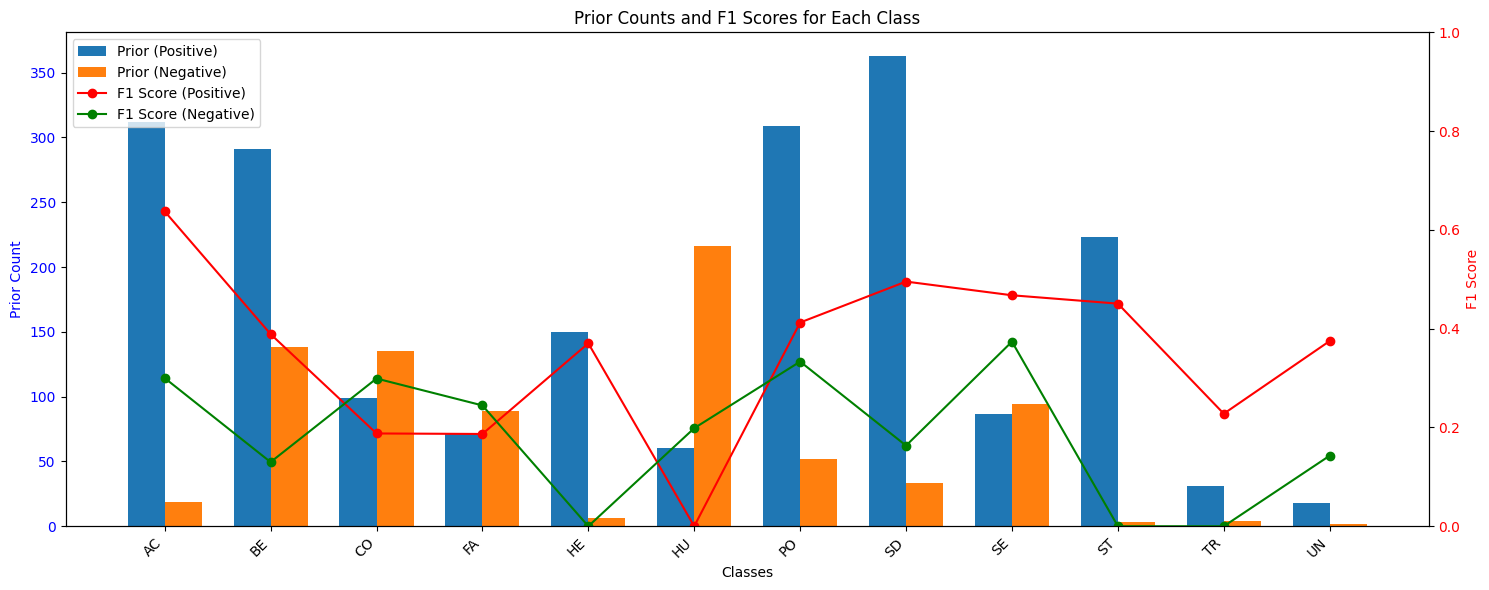

In [ ]:
# prompt: now plot 'results_df' on a graph
# x axis should be the columns (except Link1)
# y axis should have the prior count in barplot
# another y axis for the f1 scores

import matplotlib.pyplot as plt

# Create the bar plot for Prior counts
fig, ax1 = plt.subplots(figsize=(15, 6))

x_axis = results_df_reduced['Class'].unique()
bar_width = 0.35

x = np.arange(len(x_axis))

positive_prior = results_df_reduced[results_df_reduced['+\-'] == 'positive']['Prior'].values
negative_prior = results_df_reduced[results_df_reduced['+\-'] == 'negative']['Prior'].values

rects1 = ax1.bar(x - bar_width / 2, positive_prior, bar_width, label='Prior (Positive)')
rects2 = ax1.bar(x + bar_width / 2, negative_prior, bar_width, label='Prior (Negative)')

ax1.set_xlabel("Classes")
ax1.set_ylabel("Prior Count", color='b')
ax1.tick_params(axis='y', labelcolor='b')
ax1.set_xticks(x)
ax1.set_xticklabels(x_axis, rotation=45, ha='right') # Rotate x-axis labels for readability

# Create the second y-axis for F1 scores
ax2 = ax1.twinx()
f1_scores_pos = results_df_reduced[results_df_reduced['+\-'] == 'positive']['F1 Score'].values
f1_scores_neg = results_df_reduced[results_df_reduced['+\-'] == 'negative']['F1 Score'].values

ax2.plot(x, f1_scores_pos, color='r', marker='o', label='F1 Score (Positive)')
ax2.plot(x, f1_scores_neg, color='g', marker='o', label='F1 Score (Negative)')
ax2.set_ylim(0, 1)
ax2.set_ylabel("F1 Score", color='r')
ax2.tick_params(axis='y', labelcolor='r')


# Add legends and title
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc='upper left')

plt.title('Prior Counts and F1 Scores for Each Class')
plt.tight_layout()  # Adjust layout to prevent overlapping labels
plt.show()

ORIGINAL 19 VALUES

In [ ]:
import pandas as pd

def compute_class_metrics(predictions: pd.DataFrame, ground_truth: pd.DataFrame) -> pd.DataFrame:
    """
    Computes TP, TN, FP, FN, and Prior counts for each class column and value (1, -1).

    Args:
        predictions (pd.DataFrame): DataFrame containing predicted values for each class column.
        ground_truth (pd.DataFrame): DataFrame containing ground truth values for each class column.

    Returns:
        pd.DataFrame: Summary table with metrics for each class column and value (1, -1).
    """
    # Identify class columns (excluding 'id')
    class_columns = list(set(predictions.columns) & set(ground_truth.columns) - {"id", "1_Link1"})
    class_columns.sort()
    results = []

    for col in class_columns:
        for value in [1, -1]:
            # True Positives
            tp = ((predictions[col] == value) & (ground_truth[col] == value)).sum()
            # True Negatives
            tn = ((predictions[col] != value) & (ground_truth[col] != value)).sum()
            # False Positives
            fp = ((predictions[col] == value) & (ground_truth[col] != value)).sum()
            # False Negatives
            fn = ((predictions[col] != value) & (ground_truth[col] == value)).sum()
            # Prior (Count in ground truth)
            prior = (ground_truth[col] == value).sum()
            # Calculate Precision
            precision = tp / (tp + fp) if (tp + fp) > 0 else 0
            # Calculate Recall
            recall = tp / (tp + fn) if (tp + fn) > 0 else 0
            # Calculate F1 Score
            f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

            # Append results for this class and value
            results.append({
                "Class": col,
                "+\-": value,
                "TP": tp,
                "TN": tn,
                "FP": fp,
                "FN": fn,
                "Prior": prior,
                "Precision": precision,
                "Recall": recall,
                "F1 Score": f1
            })

    # Create and return the summary DataFrame
    return pd.DataFrame(results)


In [ ]:
import pandas as pd
import numpy as np

# Assuming results_df is already defined as in your provided code

def calculate_averages(results_df):
    """Calculates weighted, micro, and macro averages of F1 score."""

    # Weighted Average
    weighted_f1 = np.average(results_df['F1 Score'], weights=results_df['Prior'])

    # Micro Average
    total_tp = results_df['TP'].sum()
    total_fp = results_df['FP'].sum()
    total_fn = results_df['FN'].sum()
    micro_precision = total_tp / (total_tp + total_fp) if (total_tp + total_fp) > 0 else 0
    micro_recall = total_tp / (total_tp + total_fn) if (total_tp + total_fn) > 0 else 0
    micro_f1 = 2 * (micro_precision * micro_recall) / (micro_precision + micro_recall) if (micro_precision + micro_recall) > 0 else 0


    # Macro Average
    macro_f1 = np.mean(results_df['F1 Score'])

    return weighted_f1, micro_f1, macro_f1



In [ ]:
# change the names of class column by mapping dict
predictions_transformed = predictions_transformed.rename(columns=value_mappings)
ground_truth_transformed = ground_truth_transformed.rename(columns=value_mappings)

In [ ]:
results_df = compute_class_metrics(predictions_transformed, ground_truth_transformed)
weighted_f1, micro_f1, macro_f1 = calculate_averages(results_df)


print(results_df)

   Class  +\-   TP   TN   FP   FN  Prior  Precision    Recall  F1 Score
0     AC    1  204  453  124  108    312   0.621951  0.653846  0.637500
1     AC   -1    6  855   15   13     19   0.285714  0.315789  0.300000
2    BEC    1   61  605   97  126    187   0.386076  0.326203  0.353623
3    BEC   -1    9  771    7  102    112   0.562500  0.081081  0.141732
4    BED    1   31  670   77  111    142   0.287037  0.218310  0.248000
5    BED   -1    3  839    9   38     41   0.250000  0.073171  0.113208
6    COI    1    9  768   35   77     86   0.204545  0.104651  0.138462
7    COI   -1   18  744   20  107    125   0.473684  0.144000  0.220859
8    COR    1    3  837   39   10     13   0.071429  0.230769  0.109091
9    COR   -1    3  819   56   11     14   0.050847  0.214286  0.082192
10    FA    1   17  724   94   54     71   0.153153  0.239437  0.186813
11    FA   -1   17  767   33   72     89   0.340000  0.191011  0.244604
12    HE    1  120  361  378   30    150   0.240964  0.800000  0

In [ ]:
results_df.to_csv('results_video_18_values.csv', index=False)

In [ ]:

print("Averages for both labels")
print(f"Weighted Average F1: {weighted_f1}")
print(f"Micro Average F1: {micro_f1}")
print(f"Macro Average F1: {macro_f1}")

Averages for both labels
Weighted Average F1: 0.3425903242144565
Micro Average F1: 0.3631570275168891
Macro Average F1: 0.22259722613994046


In [ ]:
results_df_neg = results_df[results_df['+\-'] == -1]
results_df_pos = results_df[results_df['+\-'] == 1]

In [ ]:
weighted_f1, micro_f1, macro_f1 = calculate_averages(results_df_pos)

print("For 18 Values (positive)")
print(f"Weighted Average F1: {weighted_f1}")
print(f"Micro Average F1: {micro_f1}")
print(f"Macro Average F1: {macro_f1}")

For 18 Values (positive)
Weighted Average F1: 0.3921788761137445
Micro Average F1: 0.4017467248908297
Macro Average F1: 0.2895577018582612


In [ ]:
weighted_f1, micro_f1, macro_f1 = calculate_averages(results_df_neg)

print("For 18 Values (negative)")
print(f"Weighted Average F1: {weighted_f1}")
print(f"Micro Average F1: {micro_f1}")
print(f"Macro Average F1: {macro_f1}")

For 18 Values (negative)
Weighted Average F1: 0.21203343910384634
Micro Average F1: 0.21587301587301588
Macro Average F1: 0.1556367504216198


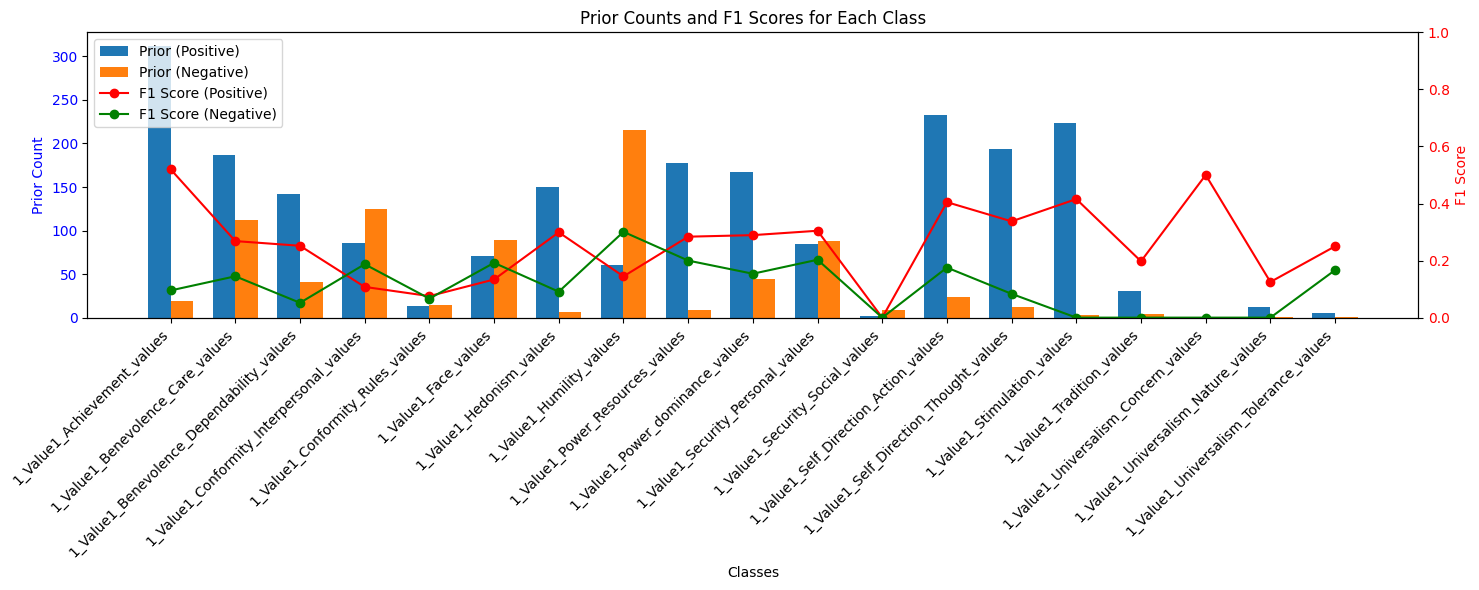

In [ ]:
# prompt: now plot 'results_df' on a graph
# x axis should be the columns (except Link1)
# y axis should have the prior count in barplot
# another y axis for the f1 scores

import matplotlib.pyplot as plt

# Create the bar plot for Prior counts
fig, ax1 = plt.subplots(figsize=(15, 6))

x_axis = results_df['Class'].unique()
bar_width = 0.35

x = np.arange(len(x_axis))

positive_prior = results_df[results_df['+\-'] == 1]['Prior'].values
negative_prior = results_df[results_df['+\-'] == -1]['Prior'].values

rects1 = ax1.bar(x - bar_width / 2, positive_prior, bar_width, label='Prior (Positive)')
rects2 = ax1.bar(x + bar_width / 2, negative_prior, bar_width, label='Prior (Negative)')

ax1.set_xlabel("Classes")
ax1.set_ylabel("Prior Count", color='b')
ax1.tick_params(axis='y', labelcolor='b')
ax1.set_xticks(x)
ax1.set_xticklabels(x_axis, rotation=45, ha='right') # Rotate x-axis labels for readability

# Create the second y-axis for F1 scores
ax2 = ax1.twinx()
f1_scores_pos = results_df[results_df['+\-'] == 1]['F1 Score'].values
f1_scores_neg = results_df[results_df['+\-'] == -1]['F1 Score'].values

ax2.plot(x, f1_scores_pos, color='r', marker='o', label='F1 Score (Positive)')
ax2.plot(x, f1_scores_neg, color='g', marker='o', label='F1 Score (Negative)')
ax2.set_ylim(0, 1)
ax2.set_ylabel("F1 Score", color='r')
ax2.tick_params(axis='y', labelcolor='r')


# Add legends and title
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc='upper left')

plt.title('Prior Counts and F1 Scores for Each Class')
plt.tight_layout()  # Adjust layout to prevent overlapping labels
plt.show()

In [ ]:
results_df.to_csv('script2val_results_df_RERUN.csv', index=False)

In [ ]:
results_df = pd.read_csv('script2val_results_df_RERUN.csv')